# Assignment 3 — IMDB Sentiment & Regularisation

**DATAX504** · Due end of Week 6

Build on **Chapter 5** (regularisation / early stopping) and **Chapter 7** (Keras `compile` / `fit`, callbacks, saving). A compact Sequential stack is fine; you may use the **Functional API** if you prefer (same depth of learning either way).

## Tasks
1. Load IMDB, pad sequences, create a train / validation split
2. Train a **baseline** sentiment model and record best validation accuracy
3. Produce a **diagram** of your model architecture (see §2b)
4. Apply **two** of: L2, dropout, early stopping — report best val accuracy and name the techniques
5. Learning-rate schedule experiment (`ReduceLROnPlateau` or `LearningRateScheduler`)
6. Save the model you consider best with `model.save(...)` and check that it reloads
7. ~200-word reflection on what you learned

## Moodle fields
`a3_repo`, `a3_baseline_val`, `a3_best_val`, `a3_techniques`, `a3_model_file`

## AI disclosure (required)
Fill the table in the next cell before you submit.

## AI disclosure

| Field | Your answer |
|-------|-------------|
| Tool / model | chatGPT |
| Used for | Helped debug setup errors (installing tensorflow/pykernel, fixing a plot_model crash), explain about this assignment and what each code does. |
| Verified how | Ran every cell myself in VS Code and checked the results |
| Not used for | Didn't use it to write code without checking it myself first|

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers, regularizers, callbacks

# Optional for plot_model (Ch 7). If import fails, use model.summary() + a drawn sketch (see §2b).
try:
    from keras.utils import plot_model
except ImportError:
    plot_model = None

## 1. Load & prepare IMDB

Hints (fill in the blanks):
- `keras.datasets.imdb.load_data(num_words=...)`
- pad both train and test with `keras.utils.pad_sequences(..., maxlen=...)`
- hold out the **first 10_000** padded training examples as validation (Ch 4 / 5 style split)
- keep the rest of the training set for fitting

In [7]:
max_features = 10000
max_len = 500

(x_train, y_train), (x_test, y_test) = keras.datasets.imdb.load_data(num_words=max_features)

# TODO: pad sequences so every review has length max_len
x_train = keras.utils.pad_sequences(x_train, maxlen=max_len)
x_test = keras.utils.pad_sequences(x_test, maxlen=max_len)

# TODO: validation split — first 10_000 samples for val, remainder for train
x_val = x_train[:10000]
y_val = y_train[:10000]
x_train = x_train[10000:]
y_train = y_train[10000:]

print("train:", getattr(x_train, "shape", None), getattr(y_train, "shape", None))
print("val:  ", getattr(x_val, "shape", None), getattr(y_val, "shape", None))
print("test: ", getattr(x_test, "shape", None), getattr(y_test, "shape", None))

train: (15000, 500) (15000,)
val:   (10000, 500) (10000,)
test:  (25000, 500) (25000,)


## 2. Baseline model

Suggested architecture (you may change widths if you document why):
1. `Embedding(max_features, 32, input_length=max_len)` — turns token ids into vectors
2. `GlobalAveragePooling1D()` — mean over the time axis
3. `Dense(32, activation="relu")`
4. `Dense(1, activation="sigmoid")` — binary sentiment

Then:
- `compile` with a suitable optimizer, **binary cross-entropy** loss, and accuracy metric
- `fit` with `validation_data=(x_val, y_val)` for ~10 epochs (batch size is your choice; 512 is common for this data)
- record the **best** validation accuracy over epochs for Moodle `a3_baseline_val`

In [8]:
def build_baseline():
    # TODO: build Sequential (or Functional) model, compile, return it
    model = keras.Sequential([
        layers.Embedding(max_features, 32),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


baseline = build_baseline()

# TODO: fit and keep the History object
hist_baseline = baseline.fit(
    x_train, y_train,
    epochs=10,
    batch_size=512,
    validation_data=(x_val, y_val),
    verbose=1,
)

# TODO: best validation accuracy across epochs
baseline_val_acc = max(hist_baseline.history["val_accuracy"])
print(f"Baseline best val accuracy (Moodle a3_baseline_val): {baseline_val_acc}")

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5452 - loss: 0.6916 - val_accuracy: 0.6771 - val_loss: 0.6879
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6397 - loss: 0.6812 - val_accuracy: 0.7056 - val_loss: 0.6714
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7001 - loss: 0.6544 - val_accuracy: 0.7325 - val_loss: 0.6353
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7307 - loss: 0.6068 - val_accuracy: 0.7103 - val_loss: 0.5855
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7341 - loss: 0.5585 - val_accuracy: 0.7727 - val_loss: 0.5329
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8087 - loss: 0.4974 - val_accuracy: 0.7764 - val_loss: 0.4909
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8311 - loss: 0.4491 - val_accuracy: 0.8336 - val_loss: 0.4392
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8426 - loss: 0.4102 - val_accuracy: 0.8358 - val_lo

## 2b. Diagram of your architecture (required)

You *can* do this with the tools from **Chapter 7 / Week 5**:

```python
keras.utils.plot_model(
    baseline,                      # or your regularised model
    to_file="imdb_model.png",      # commit this image to your repo
    show_shapes=True,
    show_layer_names=True,
)
```

Also print `model.summary()` so layer shapes appear in the notebook.

**If `plot_model` fails** (missing Graphviz / pydot on your machine):
1. Keep a full `model.summary()` output in the notebook, and
2. Add a short markdown diagram or hand-drawn photo of the stack (Embedding → … → sigmoid).

Either way, a reader should see the full forward path without reading all of your code.

In [10]:
baseline.summary()

DIAGRAM_FILE = "imdb_model.png"
diagram_ok = False
if plot_model is not None:
    try:
        plot_model(
            baseline,
            to_file=DIAGRAM_FILE,
            show_shapes=True,
            show_layer_names=True,
        )
        import os
        if os.path.exists(DIAGRAM_FILE):
            diagram_ok = True
            print(f"Wrote {DIAGRAM_FILE} — commit it to your GitHub repo")
            from IPython.display import Image, display
            display(Image(DIAGRAM_FILE))
    except Exception as e:
        print("plot_model failed — use summary + hand diagram:", e)

if not diagram_ok:
    print("Graphviz/pydot unavailable — model.summary() above satisfies the diagram requirement.")
    print("Forward path: Input -> Embedding(10000,32) -> GlobalAveragePooling1D -> Dense(32, relu) -> Dense(1, sigmoid)")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 963,269 (3.67 MB)

 Trainable params: 321,089 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 642,180 (2.45 MB)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Graphviz/pydot unavailable — model.summary() above satisfies the diagram requirement.
Forward path: Input -> Embedding(10000,32) -> GlobalAveragePooling1D -> Dense(32, relu) -> Dense(1, sigmoid)


Input review (500 padded tokens)

Embedding (10,000 words → 32-dimensional vectors)

GlobalAveragePooling1D

Dense (32 units, ReLU)

Dense (1 unit, Sigmoid)


## 3. Regularised model

Choose **exactly two** (or more if curious, but Moodle asks for two) of:

| Technique | Typical hook |
|-----------|----------------|
| L2 | `kernel_regularizer=regularizers.l2(...)` on a Dense layer |
| Dropout | `layers.Dropout(rate)` after a Dense / before the output |
| Early stopping | `callbacks.EarlyStopping(monitor="val_loss", patience=..., restore_best_weights=True)` |

Hints:
- Set boolean flags below so you can print which techniques you used
- `compile` again after building the stack
- Pass a **list of callbacks** into `fit` (empty list if you did not pick early stopping)
- Train long enough that early stopping might fire (e.g. more epochs than the baseline)
- Best val accuracy → Moodle `a3_best_val`; names → `a3_techniques`

In [11]:
USE_L2 = False          # set True if using L2
USE_DROPOUT = True      # set True if using dropout
USE_EARLY_STOP = True   # set True if using EarlyStopping

reg_model = keras.Sequential([
    layers.Embedding(max_features, 32),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

reg_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

cb = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
]

hist_reg = reg_model.fit(
    x_train, y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val),
    callbacks=cb,
    verbose=1,
)

best_val_acc = max(hist_reg.history["val_accuracy"])
techniques = []
if USE_L2:
    techniques.append("L2")
if USE_DROPOUT:
    techniques.append("dropout")
if USE_EARLY_STOP:
    techniques.append("early stopping")

print(f"Techniques (Moodle a3_techniques): {', '.join(techniques)}")
print(f"Best val accuracy (Moodle a3_best_val): {best_val_acc}")
assert len(techniques) >= 2, "Enable (at least) two techniques for full credit"

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5111 - loss: 0.6936 - val_accuracy: 0.5413 - val_loss: 0.6922
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5408 - loss: 0.6910 - val_accuracy: 0.5254 - val_loss: 0.6883
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5750 - loss: 0.6844 - val_accuracy: 0.5738 - val_loss: 0.6778
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6222 - loss: 0.6667 - val_accuracy: 0.6488 - val_loss: 0.6531
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6877 - loss: 0.6344 - val_accuracy: 0.7490 - val_loss: 0.6123
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7307 - loss: 0.5896 - val_accuracy: 0.7169 - val_loss: 0.5697
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7409 - loss: 0.5509 - val_accuracy: 0.8120 - val_loss: 0.5119
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7951 - loss: 0.4957 - val_accuracy: 0.8044 - val_

## 4. Learning-rate schedule

Week 5 / Ch 7 callback: try **`ReduceLROnPlateau`** (shrink LR when `val_loss` stalls)
or a custom **`LearningRateScheduler`**.

Hints:
- Start from the baseline or your regularised architecture (`build_baseline()` is fine)
- Put the schedule callback in the `callbacks=[...]` list for `fit`
- After training, plot the learning-rate history if present (`hist.history.get("lr", [])` for ReduceLROnPlateau)
- Short markdown below: which schedule, why those hyperparameters, what you observed

In [12]:
lr_model = build_baseline()  # rebuild a fresh model with the same architecture

lr_cb = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1
)

hist_lr = lr_model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=512,
    validation_data=(x_val, y_val),
    callbacks=[lr_cb],
    verbose=1,
)

lr_val_acc = max(hist_lr.history["val_accuracy"])
print(f"LR-schedule model best val accuracy: {lr_val_acc}")

lrs = hist_lr.history.get("lr", [])
if lrs:
    plt.plot(lrs)
    plt.xlabel("Epoch")
    plt.ylabel("Learning rate")
    plt.title("LR schedule")
    plt.show()
else:
    print("No 'lr' key in history — ReduceLROnPlateau still worked internally, just wasn't logged.")

Epoch 1/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5246 - loss: 0.6920 - val_accuracy: 0.5599 - val_loss: 0.6894 - learning_rate: 0.0010
Epoch 2/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5930 - loss: 0.6846 - val_accuracy: 0.6422 - val_loss: 0.6778 - learning_rate: 0.0010
Epoch 3/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6571 - loss: 0.6666 - val_accuracy: 0.6744 - val_loss: 0.6526 - learning_rate: 0.0010
Epoch 4/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7026 - loss: 0.6317 - val_accuracy: 0.7358 - val_loss: 0.6115 - learning_rate: 0.0010
Epoch 5/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7381 - loss: 0.5827 - val_accuracy: 0.6534 - val_loss: 0.5864 - learning_rate: 0.0010
Epoch 6/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7508 - loss: 0.5365 - val_accuracy: 0.8024 - val_loss: 0.5094 - learning_rate: 0.0010
Epoch 7/15
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8147 - loss: 0.4785 - val_accurac

**LR experiment notes** (a few sentences):

- Schedule used:

ReduceLROnPlateau, monitoring val_loss, which halves the learning rate (factor=0.5) if val_loss doesn't improve for 1 epoch (patience=1), down to a minimum of 1e-6.

- Observed effect on val curves / final accuracy:

The learning rate stayed at 0.001 for the first 11 epochs, then dropped to 0.0005 at epoch 12 after val_loss briefly worsened. After the drop, val_loss decreased more smoothly and steadily (0.397 → 0.353 → 0.339 → 0.334) compared to the more volatile earlier epochs. Best validation accuracy was 0.8681, slightly lower than the dropout + early stopping model (0.8820) but the loss curve was visibly smoother in the second half of training.

- Would you keep this schedule for a real project?

Yes — it's low-cost to add and clearly helped stabilise training once the model started to plateau, even though on its own it didn't beat dropout + early stopping for this dataset.

## 5. Save best model

Hints (Ch 7):
- Pick one of baseline / regularised / LR-tuned
- `best_model.save("something.keras")` — full architecture + weights
- `keras.models.load_model(...)` and `evaluate` on **test** once (do not retune on test)
- Commit the `.keras` file and the diagram PNG to your GitHub repo
- Filename → Moodle `a3_model_file`

In [13]:
MODEL_FILE = "imdb_sentiment_best.keras"  # Moodle a3_model_file

# TODO: choose the model object you consider best
best_model = reg_model  # or baseline or lr_model

# TODO: save
best_model.save(MODEL_FILE)

# TODO: reload and evaluate on the test set once
loaded = keras.models.load_model(MODEL_FILE)
_, test_acc = loaded.evaluate(x_test, y_test, verbose=0)

print(f"Saved model filename (Moodle a3_model_file): {MODEL_FILE}")
print(f"Test accuracy of saved model: {test_acc:.4f}")

Saved model filename (Moodle a3_model_file): imdb_sentiment_best.keras
Test accuracy of saved model: 0.8778


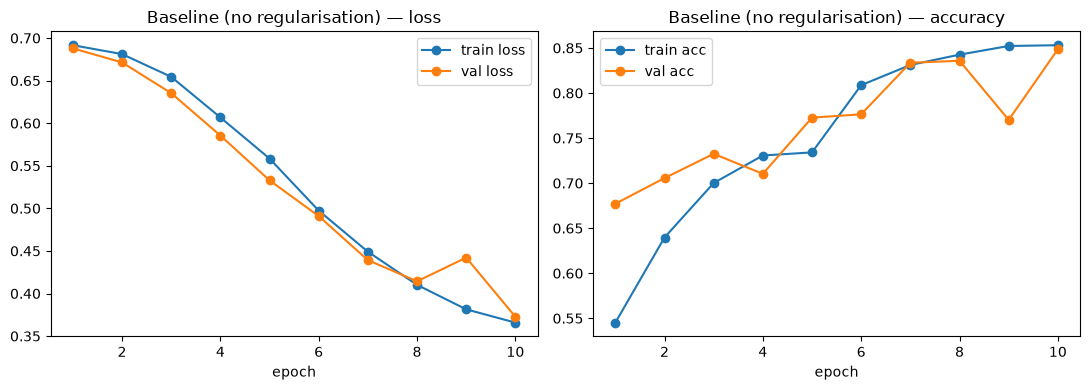

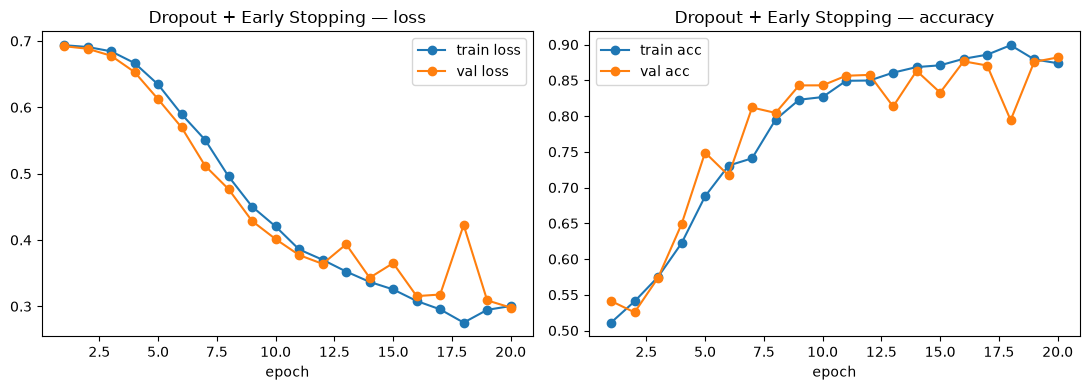

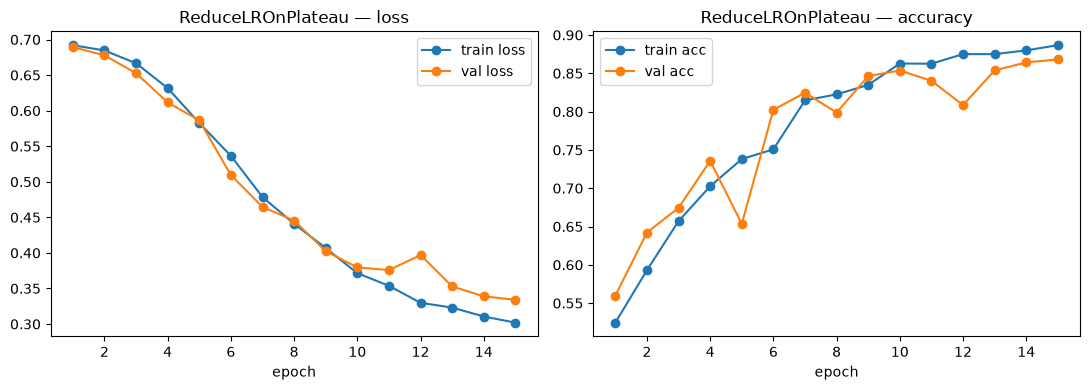

In [15]:
def plot_history(history, title):
    hist = history.history
    epochs = range(1, len(hist["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, hist["loss"], "o-", label="train loss")
    axes[0].plot(epochs, hist["val_loss"], "o-", label="val loss")
    axes[0].set_title(f"{title} — loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()

    axes[1].plot(epochs, hist["accuracy"], "o-", label="train acc")
    axes[1].plot(epochs, hist["val_accuracy"], "o-", label="val acc")
    axes[1].set_title(f"{title} — accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(hist_baseline, "Baseline (no regularisation)")
plot_history(hist_reg, "Dropout + Early Stopping")
plot_history(hist_lr, "ReduceLROnPlateau")

## 6. What did you learn?

Write ~200 words in the cell below (or paste the same text into Moodle if asked).
Cover: baseline vs regularised result, whether a technique hurt or helped, LR schedule takeaway, and one thing you would try next.

When I looked at my baseline model's loss curve, I noticed that around epoch 9, the validation loss started to spike while the training loss kept dropping. This is a sign of overfitting — the model was starting to fit noise in the training data rather than patterns that generalise. 

After adding dropout and early stopping, my validation accuracy went from 0.8485 to 0.8820, which tells me that regularisation improved results in this case, not just protected against overfitting but actually pushed accuracy higher. 

The learning rate schedule experiment showed that after the LR dropped from 0.001 to 0.0005 at epoch 12, the val loss curve became smoother and less volatile in later epochs, even though its best accuracy (0.8681) ended up lower than the dropout model.

If I extended this project, I would try a different architecture,such as an LSTM or 1D convolution instead of GlobalAveragePooling1D , because the current model completely discards word order, which likely matters a lot for judging sentiment (e.g. "not good" vs "good, not"). 

The most confusing part for me wasn't the machine learning itself, but getting the environment set up correctly — installing TensorFlow and ipykernel, and then debugging the plot_model error caused by Graphviz not being installed. It taught me that a lot of real ML work is troubleshooting the surrounding tools, not just the model code.